In [2]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn import preprocessing as p



In [5]:
%matplotlib inline

plt.rcParams['figure.figsize'] = (16, 9)



In [4]:
def simulate_data(n_samples, n_features, n_clusters, random_state=None):
    rng = np.random.default_rng(random_state)
    
    centers = rng.normal(
        loc=0,
        scale=5,
        size=(n_clusters, n_features)
    )
    
    labels = rng.integers(0, n_clusters, size=n_samples)
    data = centers[labels] + rng.normal(0, 1, size=(n_samples, n_features))
    
    return data

In [6]:
def test_simulate_data_shape(data, n_samples, n_features):
    assert data.shape == (n_samples, n_features)


def test_simulate_data_numeric(data):
    assert np.issubdtype(data.dtype, np.number)

In [7]:
data = simulate_data(200, 2, 4)
df = pd.DataFrame(data)
df.columns = ['height', 'weight']
df['height'] = np.abs(df['height']*100)
df['weight'] = df['weight'] + np.random.normal(50, 10, 200)


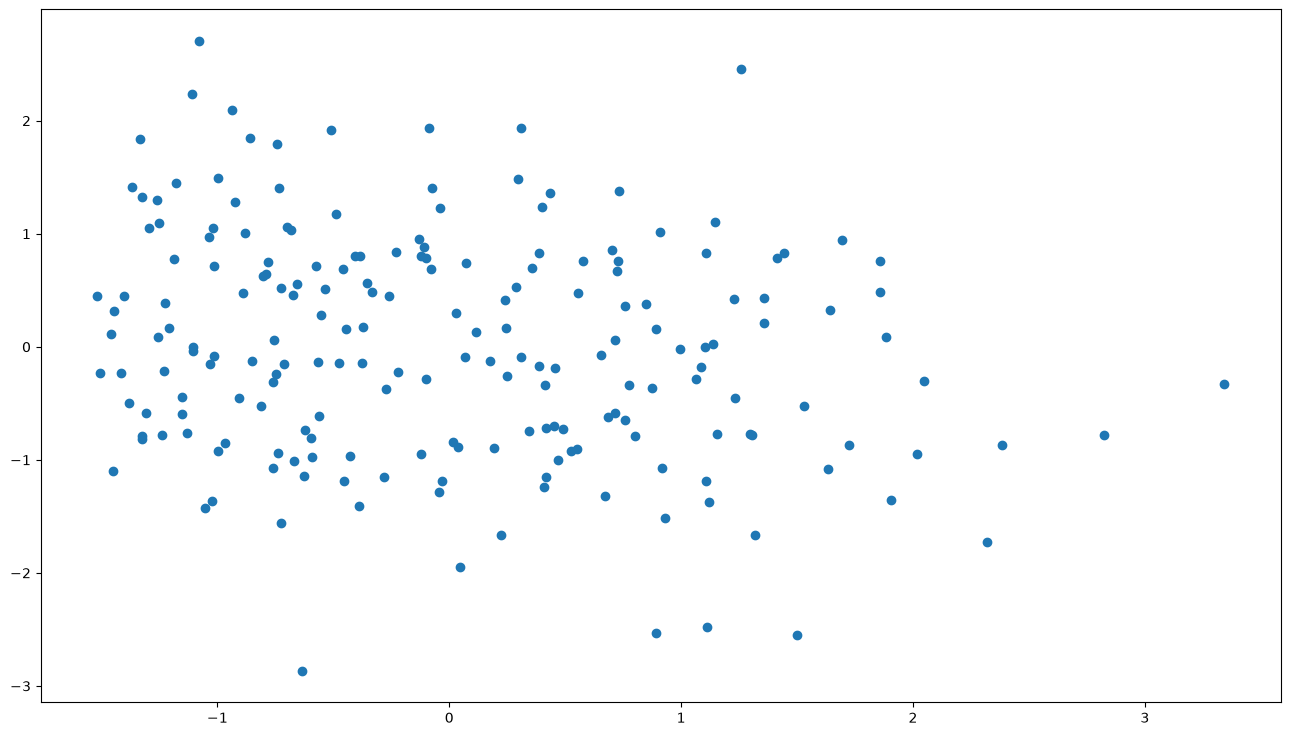

In [8]:
df_ss = p.StandardScaler().fit_transform(df) 

df_ss = pd.DataFrame(df_ss)

df_ss.columns = ['height', 'weight']

plt.scatter(df_ss['height'], df_ss['weight'])

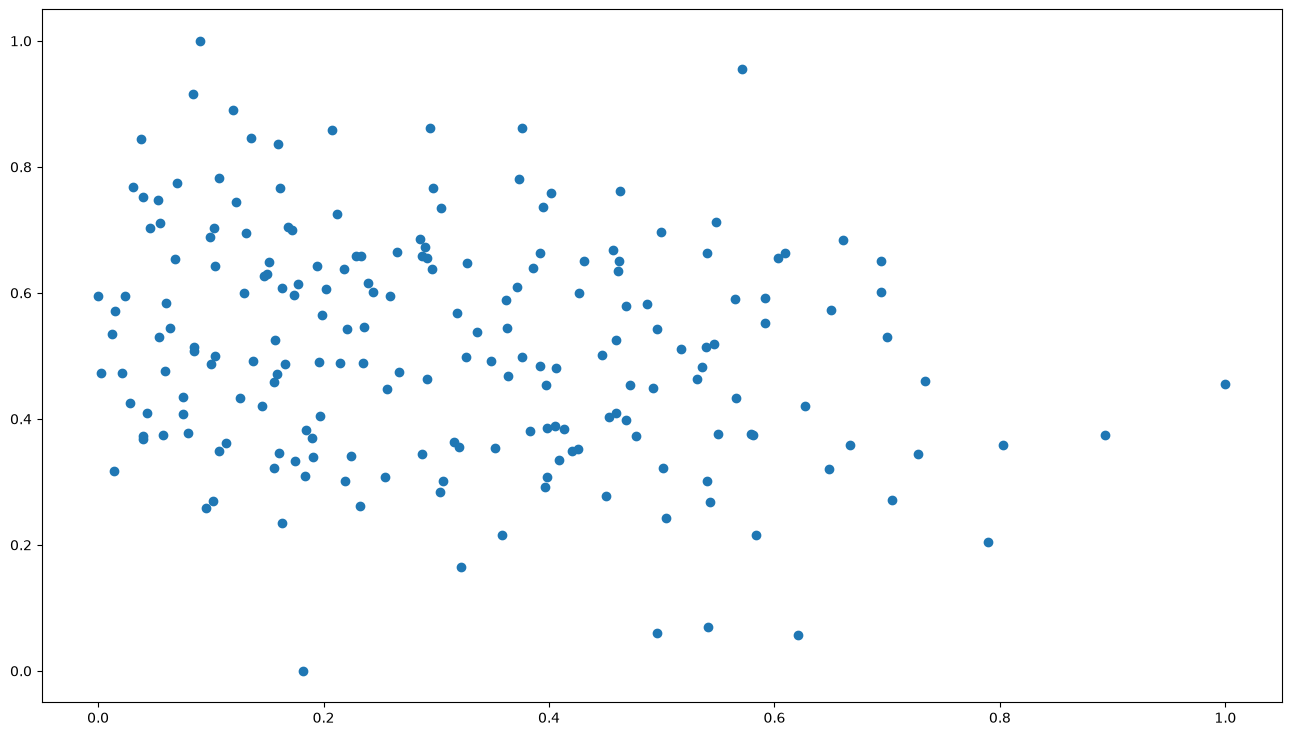

In [9]:
df_ms = p.MinMaxScaler().fit_transform(df)

df_ms = pd.DataFrame(df_ms)

df_ms.columns = ['height', 'weight']

plt.scatter(df_ms['height'], df_ms['weight'])


In [15]:
def fit_kmeans(data, centers):
    kmeans = KMeans(centers)
    kmeans.fit(data)
    labels = kmeans.predict(data)
    return labels



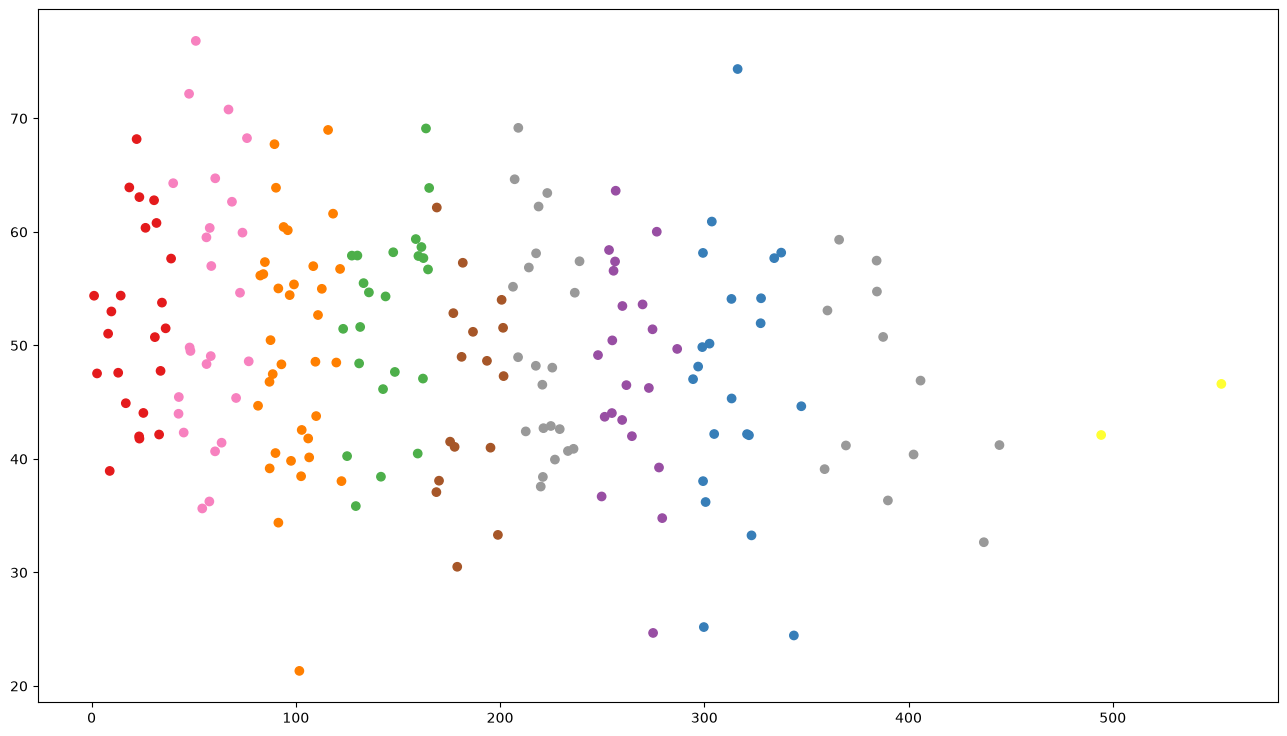

In [16]:
labels = fit_kmeans(df, 10)
plt.scatter(df['height'], df['weight'], c=labels, cmap='Set1')

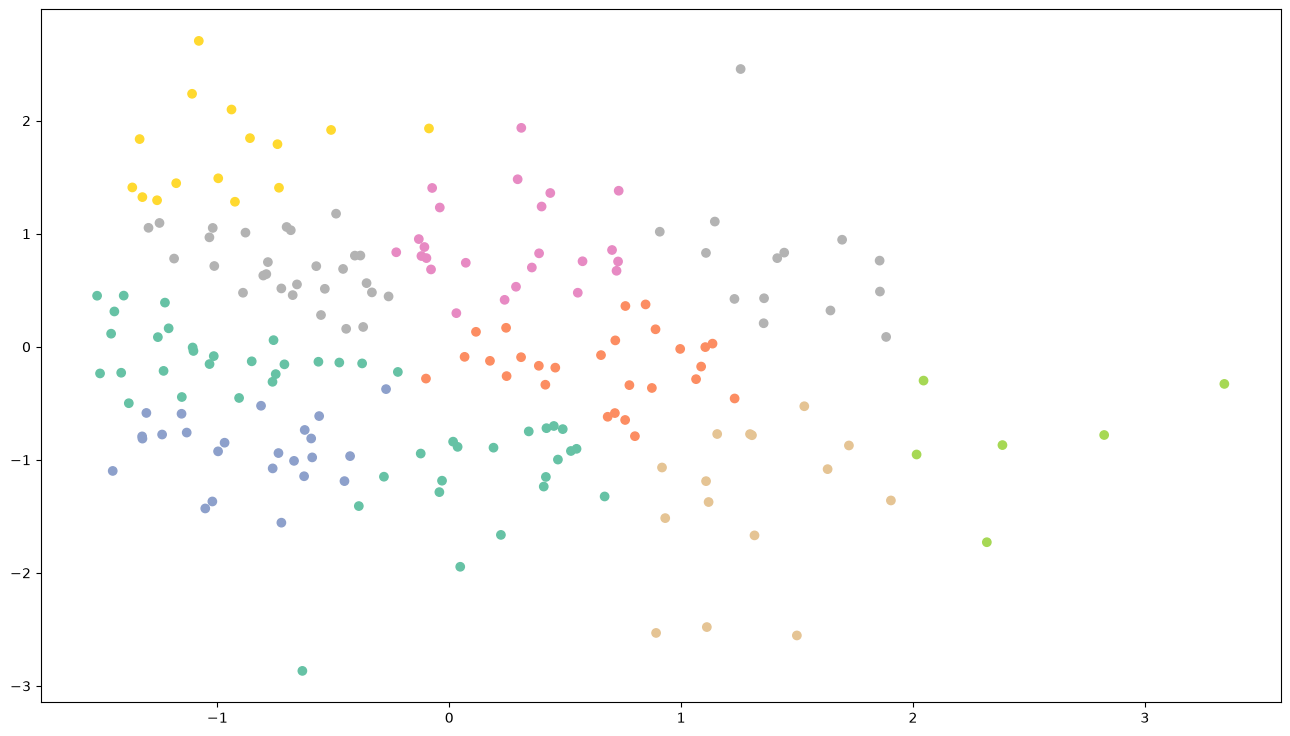

In [17]:
labels = fit_kmeans(df_ss, 10)
plt.scatter(df_ss['height'], df_ss['weight'], c=labels, cmap='Set2')

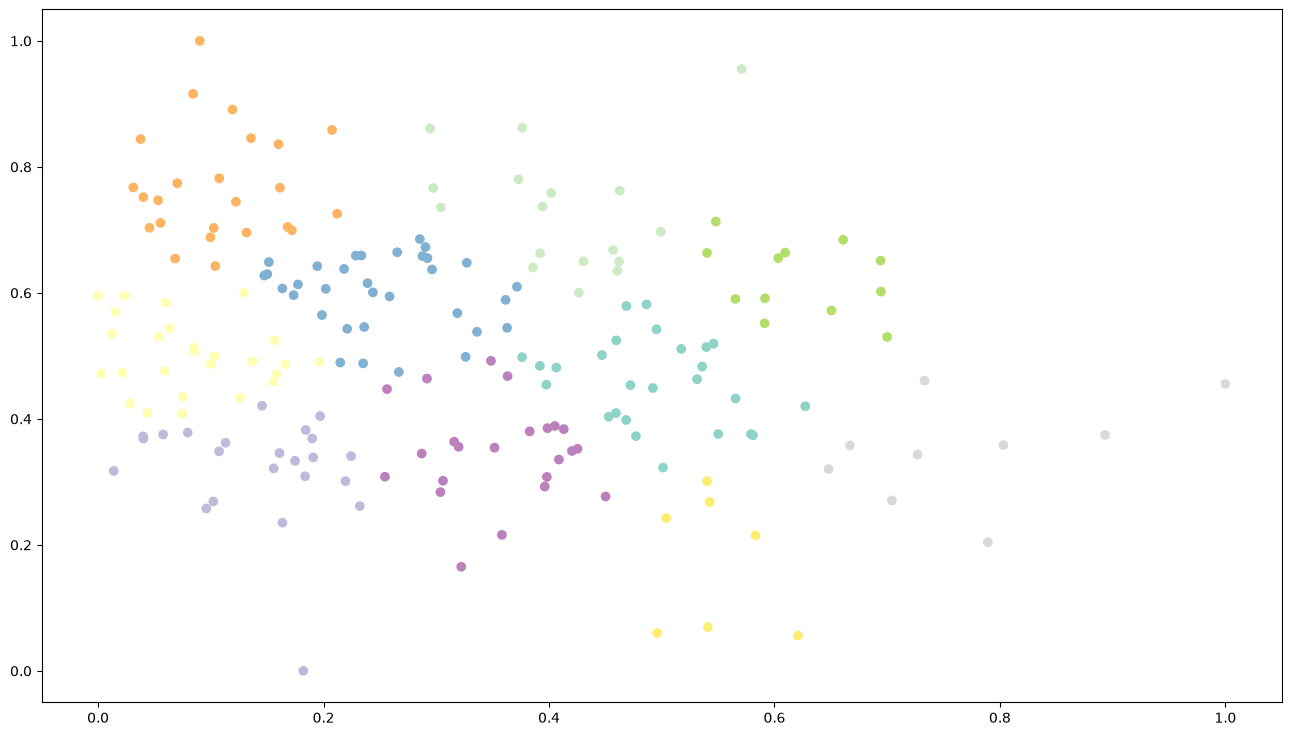

In [18]:
labels = fit_kmeans(df_ms, 10)
plt.scatter(df_ms['height'], df_ms['weight'], c=labels, cmap='Set3')